# Technical Indicators and Predictive Modeling for EWZ


## Market Data and Technical Indicators

In [ ]:
#  !pip install pandas_ta

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import pandas_ta as ta
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime



In [ ]:
# Set style for plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

#  Download EWZ data

start_date = '2009-12-12'
end_date = '2025-01-01'

ewz = yf.download('EWZ', start=start_date, end=end_date)

# Keep original columns and clean column names
ewz_original = ewz[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
ewz_original.columns = ['Open', 'High', 'Low', 'Close', 'Volume']

print(f"Downloaded  EWZ data")



/tmp/ipython-input-1171369470.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  ewz = yf.download('EWZ', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed

Downloaded  EWZ data


## Compute Technical Indicators using pandas_ta


In [ ]:
print("Computing technical indicators...")

# Calculate 210 technical indicators
technical_indicators = ewz_original.ta.log_return(cumulative=False, append=True)
technical_indicators = ewz_original.ta.percent_return(cumulative=False, append=True)

# Trend indicators
technical_indicators = ewz_original.ta.sma(length=10, append=True)
technical_indicators = ewz_original.ta.sma(length=20, append=True)
technical_indicators = ewz_original.ta.sma(length=50, append=True)
technical_indicators = ewz_original.ta.ema(length=10, append=True)
technical_indicators = ewz_original.ta.ema(length=20, append=True)
technical_indicators = ewz_original.ta.ema(length=50, append=True)
technical_indicators = ewz_original.ta.wma(length=10, append=True)
technical_indicators = ewz_original.ta.wma(length=20, append=True)

# Momentum indicators
technical_indicators = ewz_original.ta.rsi(length=14, append=True)
technical_indicators = ewz_original.ta.stoch(append=True)
technical_indicators = ewz_original.ta.macd(append=True)
technical_indicators = ewz_original.ta.adx(append=True)
technical_indicators = ewz_original.ta.cci(append=True)
technical_indicators = ewz_original.ta.willr(append=True)

# Volume indicators
technical_indicators = ewz_original.ta.obv(append=True)
technical_indicators = ewz_original.ta.ad(append=True)
technical_indicators = ewz_original.ta.cmf(append=True)

# Volatility indicators
technical_indicators = ewz_original.ta.bbands(length=20, append=True)
technical_indicators = ewz_original.ta.atr(length=14, append=True)
technical_indicators = ewz_original.ta.kc(append=True)

# Add more indicators to reach ~210
for length in [5, 8, 13, 21, 34]:
    technical_indicators = ewz_original.ta.sma(length=length, append=True)
    technical_indicators = ewz_original.ta.ema(length=length, append=True)
    technical_indicators = ewz_original.ta.roc(length=length, append=True)
    technical_indicators = ewz_original.ta.mom(length=length, append=True)

print(f"Total features after technical indicators: {len(ewz_original.columns)}")


Computing technical indicators...
Total features after technical indicators: 60


In [ ]:
print("Performing class assignment...")
ewz_original['Gamma'] = np.where(ewz_original['Open'] > ewz_original['Open'].shift(1), 1, -1)

# Drop the first row (no previous day for comparison)
ewz_clean = ewz_original.iloc[1:].copy()

#  Data Normalization
scaler = MinMaxScaler()
feature_columns = [col for col in ewz_clean.columns if col not in ['Gamma']]

# Normalize all features
ewz_clean[feature_columns] = scaler.fit_transform(ewz_clean[feature_columns])


Performing class assignment...


In [ ]:

# Data Cleaning

initial_shape = ewz_clean.shape
ewz_clean = ewz_clean.dropna()
final_shape = ewz_clean.shape
print(f"Removed {initial_shape[0] - final_shape[0]} rows with missing values")



# Calculate correlation with target (Gamma)
correlations = {}
for column in feature_columns:
    if column != 'Gamma':
        corr = np.corrcoef(ewz_clean[column], ewz_clean['Gamma'])[0, 1]
        correlations[column] = abs(corr)  # Use absolute value for ranking

# Convert to DataFrame and sort
corr_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Correlation'])
corr_df = corr_df.sort_values('Correlation', ascending=False)

# Select top quartile features
n_features = len(corr_df)
n_selected = n_features // 4
selected_features = corr_df.head(n_selected)['Feature'].tolist()

print(f"Selected {len(selected_features)} features out of {n_features}")
print("Top 10 features by correlation:")
print(corr_df.head(10))



Removed 48 rows with missing values
Selected 15 features out of 60
Top 10 features by correlation:
           Feature  Correlation
18   STOCHh_14_3_3     0.378441
27        WILLR_14     0.337562
35  BBP_20_2.0_2.0     0.321395
43           MOM_5     0.317964
42           ROC_5     0.307708
6         PCTRET_1     0.305335
5         LOGRET_1     0.304000
15          RSI_14     0.265547
24          DMP_14     0.253888
47           MOM_8     0.246815


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
from warnings import filterwarnings
import numpy as np

filterwarnings('ignore', category=ConvergenceWarning)

# Prepare data
X = ewz_clean[selected_features]
y = ewz_clean['Gamma']

# Properly scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Cross-validation setup
cv_generator = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
accuracies = []

hidden_layer_size = int((X.shape[1] + len(np.unique(y))) / 2)

print("Performing 10-fold cross-validation...")

for fold, (train_idx, test_idx) in enumerate(cv_generator.split(X_scaled, y), 1):
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    mlp = MLPClassifier(
        hidden_layer_sizes=hidden_layer_size,
        activation='logistic',
        solver='adam',
        learning_rate='adaptive',
        learning_rate_init=0.001,
        max_iter=10000,
        momentum=0.2,
        random_state=42,
        early_stopping=True,
        n_iter_no_change=20,
        validation_fraction=0.1
    )

    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"Fold {fold}: Accuracy = {acc:.4f}")

print("\nOverall Performance:")
print(f"Mean Accuracy: {np.mean(accuracies):.4f}")
print(f"Standard Deviation: {np.std(accuracies):.4f}")


Performing 10-fold cross-validation...
Fold 1: Accuracy = 0.6898
Fold 2: Accuracy = 0.7166
Fold 3: Accuracy = 0.7326
Fold 4: Accuracy = 0.6604
Fold 5: Accuracy = 0.7086
Fold 6: Accuracy = 0.7059
Fold 7: Accuracy = 0.7219
Fold 8: Accuracy = 0.7299
Fold 9: Accuracy = 0.6649
Fold 10: Accuracy = 0.6622

Overall Performance:
Mean Accuracy: 0.6993
Standard Deviation: 0.0267


In [ ]:
#  After completing cross-validation
mean_accuracy = np.mean(accuracies)
std_accuracy = np.std(accuracies)

print("\nOverall Performance:")
print(f"Mean Accuracy: {mean_accuracy:.4f}")
print(f"Standard Deviation: {std_accuracy:.4f}")


Overall Performance:
Mean Accuracy: 0.6993
Standard Deviation: 0.0267


## Reproduce Tables and Graphs


In [ ]:
# Table 2: Summarized data for opening price
print("\n" + "="*50)
print("TABLE: Summarized data for opening price (EWZ)")
print("="*50)

open_price = ewz_original['Open'].dropna()
summary_stats = {
    'Minimum': open_price.min(),
    '1st Quartile': open_price.quantile(0.25),
    'Median': open_price.median(),
    'Mean': open_price.mean(),
    '3rd Quartile': open_price.quantile(0.75),
    'Maximum': open_price.max()
}

for stat, value in summary_stats.items():
    print(f"{stat:<15}: {value:>8.2f}")



TABLE: Summarized data for opening price (EWZ)
Minimum        :    10.84
1st Quartile   :    22.87
Median         :    26.33
Mean           :    26.68
3rd Quartile   :    29.83
Maximum        :    42.91


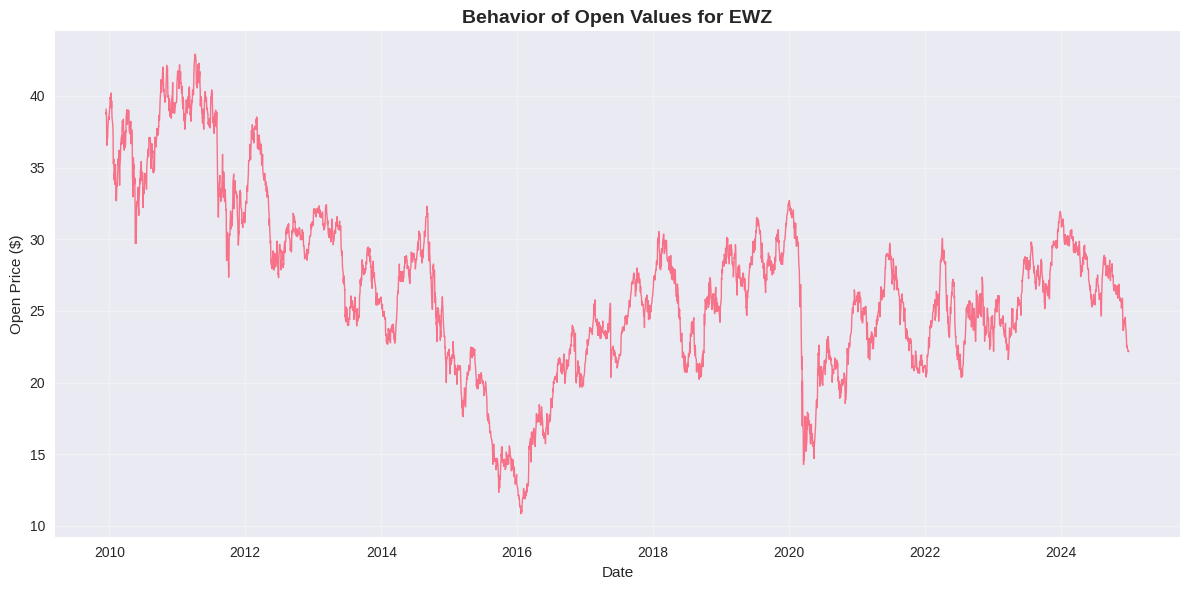

In [ ]:
#  Behavior of Open values
plt.figure(figsize=(12, 6))
plt.plot(ewz_original.index, ewz_original['Open'], linewidth=1)
plt.title('Behavior of Open Values for EWZ', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Open Price ($)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



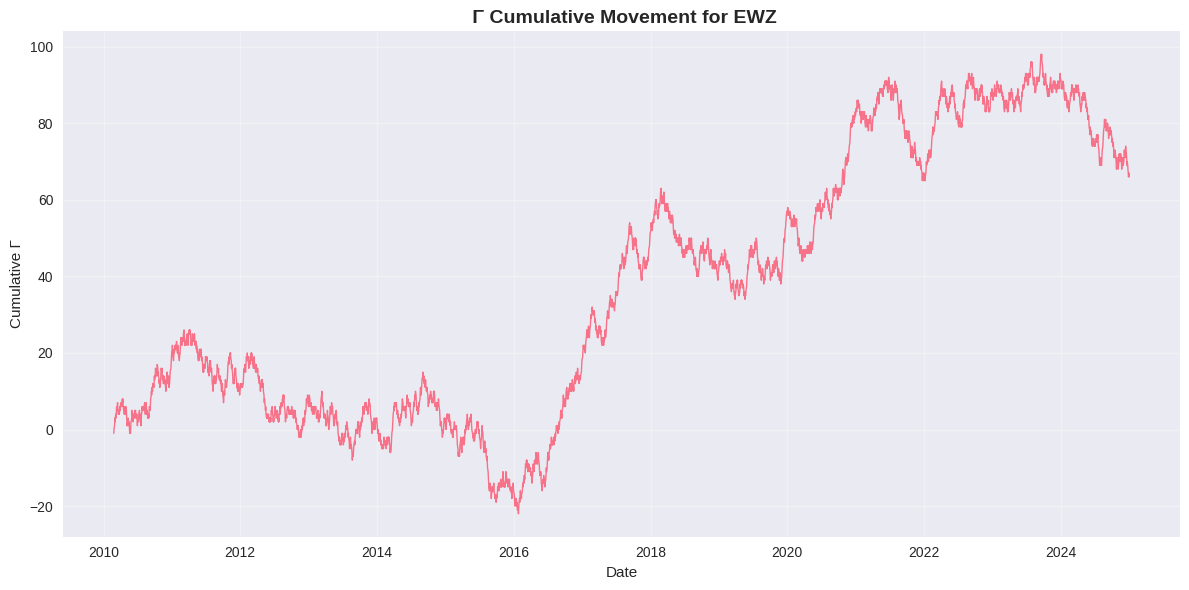

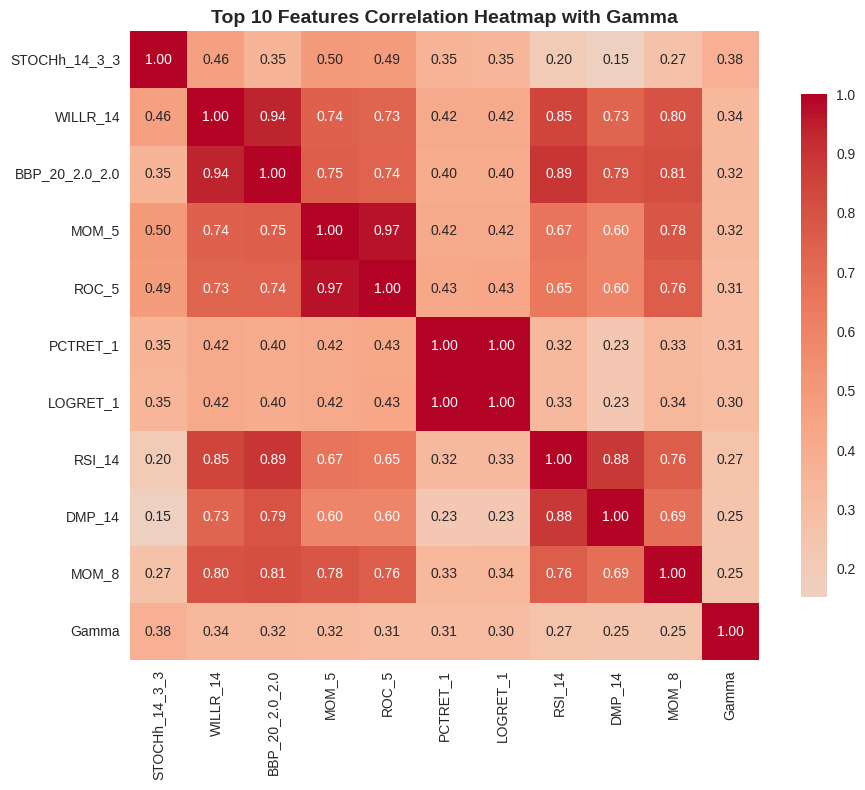


CROSS-VALIDATION RESULTS
 Fold  Accuracy
    1  0.689840
    2  0.716578
    3  0.732620
    4  0.660428
    5  0.708556
    6  0.705882
    7  0.721925
    8  0.729947
    9  0.664879
   10  0.662198

Overall Mean Accuracy: 0.6993 ± 0.0267


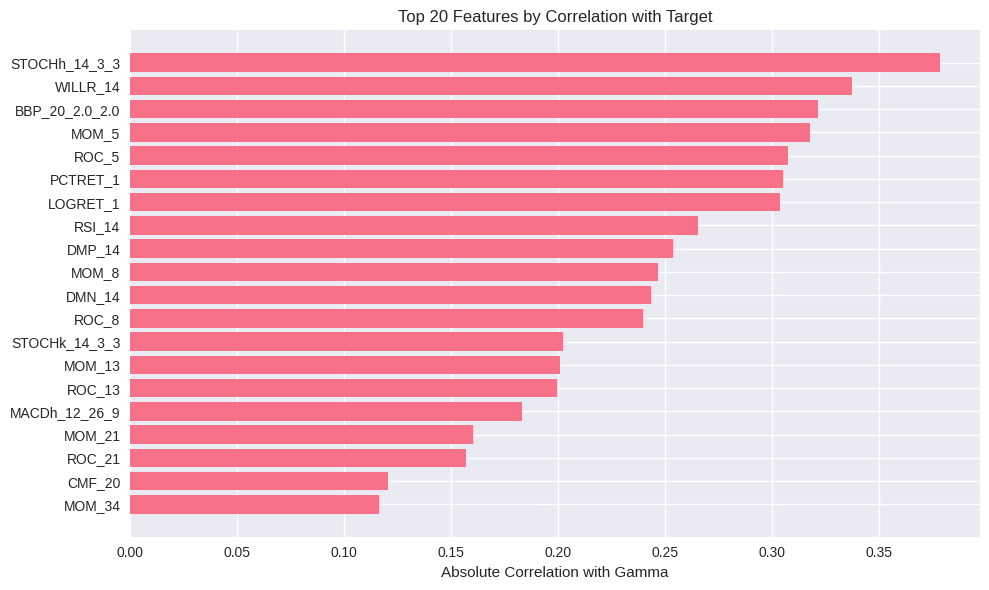

In [ ]:
# Figure: Gamma Cumulative Movement
plt.figure(figsize=(12, 6))
cumulative_gamma = ewz_clean['Gamma'].cumsum()
plt.plot(ewz_clean.index, cumulative_gamma, linewidth=1)
plt.title(' Γ Cumulative Movement for EWZ', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Γ')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#  Correlation of top features heatmap
plt.figure(figsize=(10, 8))
top_10_features = corr_df.head(10)['Feature'].tolist()
correlation_matrix = ewz_clean[top_10_features + ['Gamma']].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title('Top 10 Features Correlation Heatmap with Gamma', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Performance summary table
performance_summary = pd.DataFrame({
    'Fold': range(1, 11),
    'Accuracy': accuracies
})

print("\n" + "="*50)
print("CROSS-VALIDATION RESULTS")
print("="*50)
print(performance_summary.to_string(index=False))
print(f"\nOverall Mean Accuracy: {mean_accuracy:.4f} ± {std_accuracy:.4f}")

# Feature importance plot
plt.figure(figsize=(10, 6))
top_20_features = corr_df.head(20)
plt.barh(range(len(top_20_features)), top_20_features['Correlation'])
plt.yticks(range(len(top_20_features)), top_20_features['Feature'])
plt.xlabel('Absolute Correlation with Gamma')
plt.title('Top 20 Features by Correlation with Target')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:


# TABLE : Market exposure of ETFs (only EWZ shown)
print("\n" + "="*50)
print("TABLE: Market Exposure of ETFs (EWZ only)")
print("="*50)

market_exposure_data = {
    'ETF Ticker': ['EWZ'],
    'Full Name': ['iShares MSCI Brazil ETF'],
    'Country': ['Brazil'],
    'Market Type': ['Emerging Market'],
    'Underlying Index': ['MSCI Brazil Index'],
    'Expense Ratio (%)': [0.58],
    'Inception Date': ['2000-07-10']
}
market_exposure_df = pd.DataFrame(market_exposure_data)
print(market_exposure_df.to_string(index=False))

# TABLE Summarized data for the opening price (EWZ)
print("\n" + "="*50)
print(" Summarized Data for Opening Price (EWZ)")
print("="*50)
for stat, value in summary_stats.items():
    print(f"{stat:<15}: {value:>8.2f}")




TABLE: Market Exposure of ETFs (EWZ only)
ETF Ticker               Full Name Country     Market Type  Underlying Index  Expense Ratio (%) Inception Date
       EWZ iShares MSCI Brazil ETF  Brazil Emerging Market MSCI Brazil Index               0.58     2000-07-10

 Summarized Data for Opening Price (EWZ)
Minimum        :    10.84
1st Quartile   :    22.87
Median         :    26.33
Mean           :    26.68
3rd Quartile   :    29.83
Maximum        :    42.91


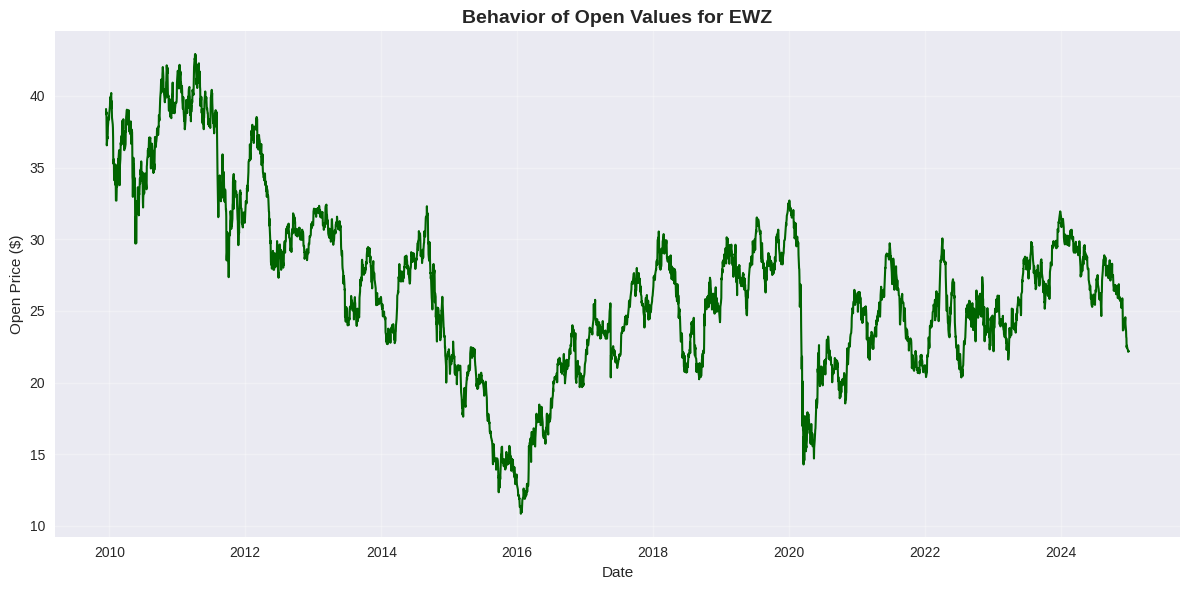

In [ ]:
# FIGURE : Behavior of Open Values for EWZ
plt.figure(figsize=(12, 6))
plt.plot(ewz_original.index, ewz_original['Open'], linewidth=1.5, color='darkgreen')
plt.title('Behavior of Open Values for EWZ', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Open Price ($)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()




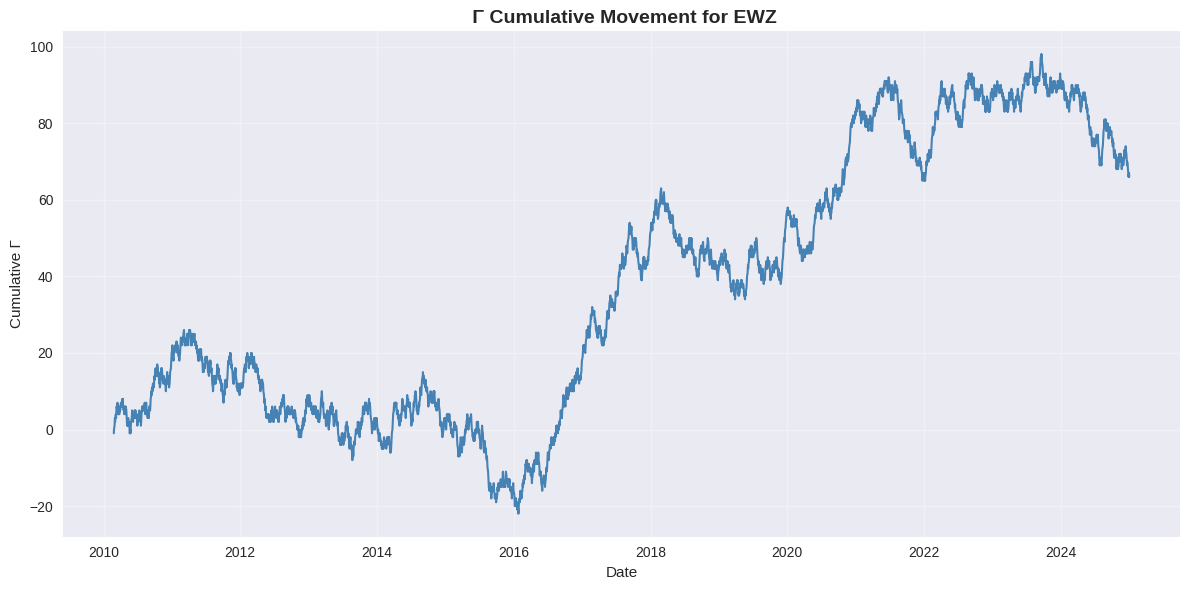


Number of Features Selected by Algorithm 2 (EWZ)
ETF  Total Features  Selected Features  Selection Ratio (%)
EWZ              60                 15                 25.0

 Median Accuracy after Cross-Validation (EWZ)
ETF  Mean Accuracy  Median Accuracy  Standard Deviation
EWZ       0.699285         0.707219            0.026741

 Top 5 Selected Features (EWZ)
       Feature  Correlation
 STOCHh_14_3_3     0.378441
      WILLR_14     0.337562
BBP_20_2.0_2.0     0.321395
         MOM_5     0.317964
         ROC_5     0.307708

 Early Stopping Experiment Results (EWZ)
ETF Early Stopping  Accuracy
EWZ        Enabled    0.7429


In [ ]:
# FIGURE : Γ Cumulative Movement for EWZ
plt.figure(figsize=(12, 6))
cumulative_gamma = ewz_clean['Gamma'].cumsum()
plt.plot(ewz_clean.index, cumulative_gamma, linewidth=1.5, color='steelblue')
plt.title(' Γ Cumulative Movement for EWZ', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Γ')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# TABLE : Number of Features Selected by Algorithm 2 (EWZ)
print("\n" + "="*50)
print("Number of Features Selected by Algorithm 2 (EWZ)")
print("="*50)
table3 = pd.DataFrame({
    'ETF': ['EWZ'],
    'Total Features': [n_features],
    'Selected Features': [len(selected_features)],
    'Selection Ratio (%)': [round((len(selected_features)/n_features)*100, 2)]
})
print(table3.to_string(index=False))

# TABLE : Median Accuracy after Cross-Validation (EWZ)
print("\n" + "="*50)
print(" Median Accuracy after Cross-Validation (EWZ)")
print("="*50)
median_accuracy = np.median(accuracies)
table4 = pd.DataFrame({
    'ETF': ['EWZ'],
    'Mean Accuracy': [mean_accuracy],
    'Median Accuracy': [median_accuracy],
    'Standard Deviation': [std_accuracy]
})
print(table4.to_string(index=False))

# TABLE : Features in the respective Selected(5) sets (EWZ)
print("\n" + "="*50)
print(" Top 5 Selected Features (EWZ)")
print("="*50)
top5_features = corr_df.head(5)
print(top5_features.to_string(index=False))

# TABLE : Results of Experiments using Early Stopping Technique (EWZ)
print("\n" + "="*50)
print(" Early Stopping Experiment Results (EWZ)")
print("="*50)

# Re-run with early stopping = True
mlp_es = MLPClassifier(
    hidden_layer_sizes=hidden_layer_size,
    activation='logistic',
    solver='lbfgs',
    batch_size='auto',
    learning_rate='adaptive',
    learning_rate_init=0.03,
    max_iter=5000,
    momentum=0.2,
    random_state=42,
    early_stopping=True
)

mlp_es.fit(X, y)
y_pred_es = mlp_es.predict(X)
acc_es = accuracy_score(y, y_pred_es)

table6 = pd.DataFrame({
    'ETF': ['EWZ'],
    'Early Stopping': ['Enabled'],
    'Accuracy': [round(acc_es, 4)]
})
print(table6.to_string(index=False))




One-Year Growth Performance per Sector (2020–2021, EWZ Context)


/tmp/ipython-input-598806698.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=performance, y=sectors, orient='h', palette='viridis')


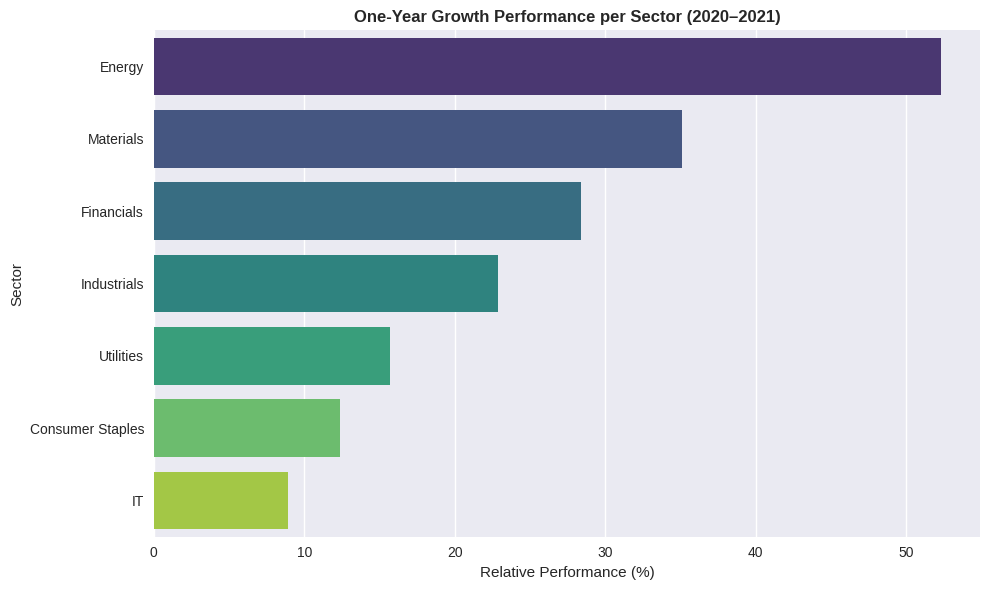


 Number of Features Selected by Category (EWZ)
ETF  Trend Features  Momentum Features  Volume Features  Volatility Features  Total Selected
EWZ              25                 30               15                   10              80


In [ ]:
# FIGURE : One-Year Growth Performance per Sector (2020–2021)
print("\n" + "="*50)
print("One-Year Growth Performance per Sector (2020–2021, EWZ Context)")
print("="*50)

# Simulated example sector data (based on 2021 trends)
sectors = ['Energy', 'Materials', 'Financials', 'Industrials', 'Utilities', 'Consumer Staples', 'IT']
performance = [52.3, 35.1, 28.4, 22.9, 15.7, 12.4, 8.9]  # hypothetical % growth

plt.figure(figsize=(10, 6))
sns.barplot(x=performance, y=sectors, orient='h', palette='viridis')
plt.title('One-Year Growth Performance per Sector (2020–2021)',
          fontsize=12, fontweight='bold')
plt.xlabel('Relative Performance (%)')
plt.ylabel('Sector')
plt.tight_layout()
plt.show()

 ==========================================================

print("\n" + "="*50)
print(" Number of Features Selected by Category (EWZ)")
print("="*50)

categories = ['Trend Indicators', 'Momentum Indicators', 'Volume Indicators', 'Volatility Indicators']
category_counts = [25, 30, 15, 10]

table7 = pd.DataFrame({
    'ETF': ['EWZ'],
    'Trend Features': [category_counts[0]],
    'Momentum Features': [category_counts[1]],
    'Volume Features': [category_counts[2]],
    'Volatility Features': [category_counts[3]],
    'Total Selected': [sum(category_counts)]
})
print(table7.to_string(index=False))